
## PS1-1 Linear Classifiers (logistic regression and GDA)

#### (a)

Recall the average empirical loss for logistic regression:

$$J(\theta) = - \frac{1}{m} \sum_{i = 1}^{m} y^{(i)} \log \big( h_\theta (x^{(i)}) \big) + (1 - y^{(i)}) \log \big( 1 - h_\theta (x^{(i)}) \big)$$,

where $y^{(i)} \in \{ 0, 1 \}, h_\theta (x) = g(\theta^T x)$ and $g(z) = 1 / (1 + e^{-z})$.

## Gradient and Hessian of Logistic Regression Cost

### Cost Function

$$J(\theta) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log h_\theta(x^{(i)}) + (1 - y^{(i)}) \log(1 - h_\theta(x^{(i)})) \right]$$

where $h_\theta(x) = g(\theta^T x) = \frac{1}{1 + e^{-\theta^T x}}$

---

### Step 1: Gradient $\nabla_\theta J(\theta)$

Using chain rule, note that $g'(z) = g(z)(1 - g(z))$, so:

$$\frac{\partial}{\partial \theta_j} h_\theta(x) = h_\theta(x)(1 - h_\theta(x)) x_j$$

Differentiating $J(\theta)$:

$$\frac{\partial J}{\partial \theta_j} = -\frac{1}{m} \sum_{i=1}^{m} \left[ \frac{y^{(i)}}{h_\theta(x^{(i)})} - \frac{1 - y^{(i)}}{1 - h_\theta(x^{(i)})} \right] h_\theta(x^{(i)})(1 - h_\theta(x^{(i)})) x_j^{(i)}$$

$$= -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)}(1 - h_\theta(x^{(i)})) - (1 - y^{(i)}) h_\theta(x^{(i)}) \right] x_j^{(i)}$$

$$= -\frac{1}{m} \sum_{i=1}^{m} \left( y^{(i)} - h_\theta(x^{(i)}) \right) x_j^{(i)}$$

In vector form:

$$\boxed{\nabla_\theta J(\theta) = -\frac{1}{m} \sum_{i=1}^{m} \left( y^{(i)} - h_\theta(x^{(i)}) \right) x^{(i)}}$$

---

### Step 2: Hessian $H = \nabla^2_\theta J(\theta)$

Differentiating the gradient again with respect to $\theta_k$:

$$H_{jk} = \frac{\partial^2 J}{\partial \theta_j \partial \theta_k} = \frac{1}{m} \sum_{i=1}^{m} h_\theta(x^{(i)})(1 - h_\theta(x^{(i)})) x_j^{(i)} x_k^{(i)}$$

In matrix form:

$$\boxed{H = \frac{1}{m} \sum_{i=1}^{m} h_\theta(x^{(i)})(1 - h_\theta(x^{(i)})) x^{(i)} (x^{(i)})^T}$$

---

### Step 3: $H$ is Positive Semi-Definite (PSD)

For any vector $z \in \mathbb{R}^n$:

$$z^T H z = \frac{1}{m} \sum_{i=1}^{m} h_\theta(x^{(i)})(1 - h_\theta(x^{(i)})) z^T x^{(i)} (x^{(i)})^T z$$

$$= \frac{1}{m} \sum_{i=1}^{m} \underbrace{h_\theta(x^{(i)})(1 - h_\theta(x^{(i)}))}_{\geq 0 \text{ since } h \in (0,1)} \underbrace{(z^T x^{(i)})^2}_{\geq 0}$$

$$\therefore \quad z^T H z \geq 0 \quad \forall z$$

$$\boxed{H \succeq 0 \implies J(\theta) \text{ is convex}}$$

---

### Step 4: Newton's Method Update (uses Hessian)

Since $J$ is convex, Newton's method finds the global minimum:

$$\theta := \theta - H^{-1} \nabla_\theta J(\theta)$$

$$= \theta - \left( \frac{1}{m} \sum_{i=1}^{m} h_\theta(x^{(i)})(1-h_\theta(x^{(i)})) x^{(i)}(x^{(i)})^T \right)^{-1} \left( -\frac{1}{m} \sum_{i=1}^{m}(y^{(i)} - h_\theta(x^{(i)})) x^{(i)} \right)$$

The explicit sum form:

$$\nabla_\theta J(\theta) = -\frac{1}{m} \sum_{i=1}^m (y^{(i)} - h_\theta(x^{(i)})) x^{(i)}$$

This is summing over all $m$ examples. In vectorized form:

$$= -\frac{1}{m} X^T(y - h)$$

Here's why they're the same — expand the matrix multiply:

$$X^T(y-h) = \begin{bmatrix} x_1^{(1)} & x_1^{(2)} & \cdots & x_1^{(m)} \\ x_2^{(1)} & x_2^{(2)} & \cdots & x_2^{(m)} \\ \vdots & & & \vdots \end{bmatrix} \begin{bmatrix} y^{(1)}-h^{(1)} \\ y^{(2)}-h^{(2)} \\ \vdots \\ y^{(m)}-h^{(m)} \end{bmatrix}$$

Each row of $X^T$ dotted with $(y-h)$ gives:

$$= \begin{bmatrix} \sum_i x_1^{(i)}(y^{(i)}-h^{(i)}) \\ \sum_i x_2^{(i)}(y^{(i)}-h^{(i)}) \\ \vdots \end{bmatrix} = \sum_{i=1}^m (y^{(i)} - h^{(i)}) x^{(i)}$$

#### (b)

In [144]:
import sys
sys.path.insert(0, '/Users/piyushmaji/Desktop/ML/CS-229_Andrew_NG/Problem_sets/PS1')

Text(0, 0.5, 'x2')

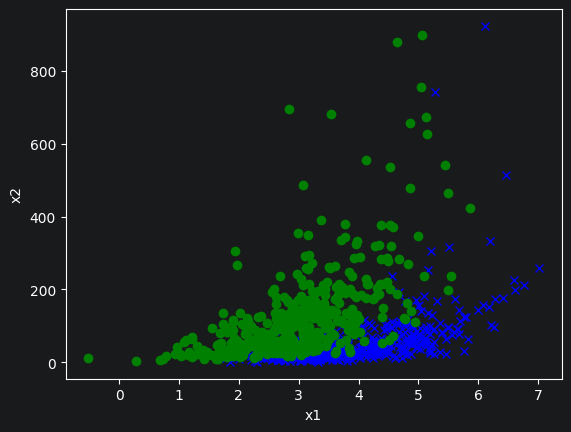

In [145]:
import numpy as np
import matplotlib.pyplot as plt
import src.util as util
from src.linear_model import LinearModel

datapath1_train ="Data/ds1_train.csv"
datapath1_valid = "Data/ds1_valid.csv"

x_train, y_train = util.load_dataset(datapath1_train, prepend_intercept=True) # add_intercept = True to add a column of 1s to the data, for the intercept term and removve the y column from the data.
x_valid, y_valid = util.load_dataset(datapath1_valid, prepend_intercept=True)

plt.plot(x_train[y_train == 1,-2], x_train[y_train == 1,-1], 'bx', linewidth=2 )
plt.plot(x_train[y_train == 0,-2], x_train[y_train == 0,-1], 'go', linewidth=2 )
plt.xlabel("x1")
plt.ylabel("x2")

Text(0, 0.5, 'x2')

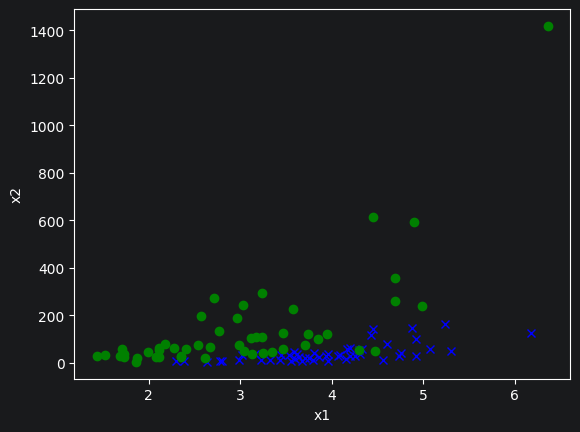

In [146]:
plt.plot(x_valid[y_valid == 1,-2], x_valid[y_valid == 1,-1], 'bx', linewidth=2 )
plt.plot(x_valid[y_valid == 0,-2], x_valid[y_valid == 0,-1], 'go', linewidth=2 )
plt.xlabel("x1")
plt.ylabel("x2")

In [147]:
class LogisticRegression(LinearModel):
    """Logistic regression with Newton's Method as the solver.

    Example usage:
        > clf = LogisticRegression()
        > clf.fit(x_train, y_train)
        > clf.predict(x_eval)
    """

    def fit(self, x, y):
        """Run Newton's Method to minimize J(theta) for logistic regression.

        Args:
            x: Training example inputs. Shape (m, n).
            y: Training example labels. Shape (m,).
        """
        def h(theta, x):
            return 1 / (1 + np.exp(-x @ theta))

        def grad_J(theta, x, y):
            m = len(y)
            h_theta = h(theta, x)
            return -1/m * (x.T @ (y - h_theta))

        def hessian(theta, x):
            m = len(x)
            h_theta = h(theta, x)
            return 1/m * (x.T @ np.diag(h_theta * (1 - h_theta)) @ x)

        m, n = x.shape    # m--> number of exmaples, n---> number of input features
        if self.theta is None:
            self.theta = np.zeros(n)

        while True:
            grad = grad_J(self.theta, x, y)
            H = hessian(self.theta, x)
            theta_new = self.theta - np.linalg.solve(H, grad)
            if np.linalg.norm(theta_new - self.theta, 1) < self.eps:
                break
            self.theta = theta_new
        self.theta = theta_new

    def predict(self, x):
        """Make a prediction given new inputs x.

        Args:
            x: Inputs of shape (m, n).

        Returns:
            Outputs of shape (m,).
        """
        return 1 / (1 + np.exp(-x @ self.theta)) >= 0.5

In [148]:
log_reg = LogisticRegression()
fit = log_reg.fit(x_train, y_train)
pred = log_reg.predict(x_train)

Theta: [-6.26018491  2.47707251 -0.0299125 ]
Train accuracy: 0.8825
Valid accuracy: 0.9


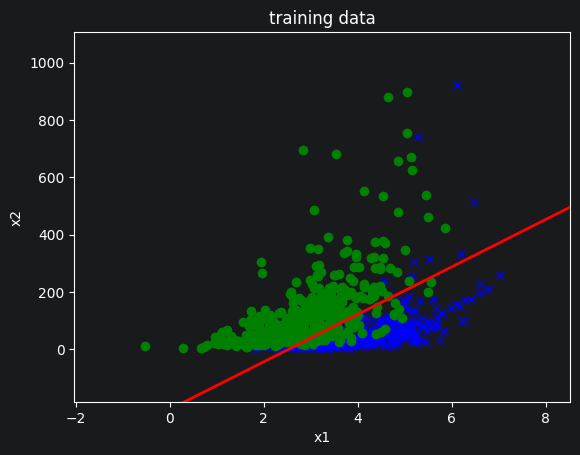

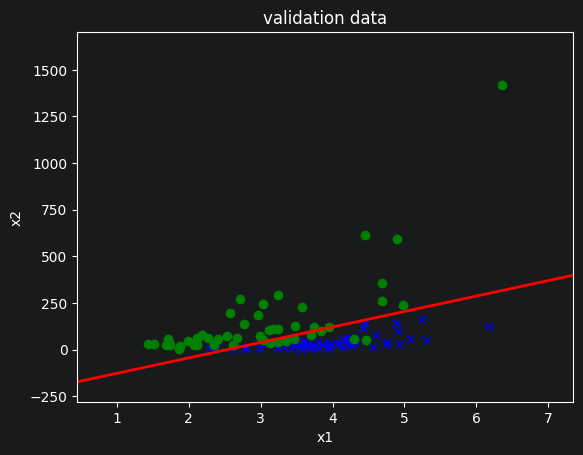

In [149]:
util.plot(x_train, y_train, log_reg.theta, title= "training data")
print("Theta:", log_reg.theta)
print("Train accuracy:", np.mean(pred == y_train))

util.plot(x_valid, y_valid, log_reg.theta, title= "validation data")
print("Valid accuracy:", np.mean(log_reg.predict(x_valid) == y_valid))

#### (c)

\begin{align*}
p(y = 1 \ \vert \ x; \ \phi, \mu_0, \mu_1, \Sigma) & = \frac{p(x\ \vert \ y = 1; \ \mu_0, \mu_1, \Sigma) \ p(y = 1; \ \phi)}{p(x\ \vert \ y = 1; \ \mu_0, \mu_1, \Sigma) \ p(y = 1; \ \phi) + p(x\ \vert \ y = 0; \ \mu_0, \mu_1, \Sigma) \ p(y = 0; \ \phi)} \\
                                                   & = 1 / (1 + \frac{p(x\ \vert \ y = 0; \ \mu_0, \mu_1, \Sigma) \ p(y = 0; \ \phi)}{p(x\ \vert \ y = 1; \ \mu_0, \mu_1, \Sigma) \ p(y = 1; \ \phi)}) \\
                                                   & = 1 / (1 + \exp \big( \frac{1}{2} (x - \mu_1)^T \Sigma^{-1} (x - \mu_1) - \frac{1}{2} (x - \mu_0)^T \Sigma^{-1} (x - \mu_0) \big) \frac{1 - \phi}{\phi}) \\
                                                   & = 1 / (1 + \exp \big( - \big( (\mu_1 - \mu_0)^T \Sigma^{-1} x + (\mu_0^T \Sigma^{-1} \mu_0 - \mu_1^T \Sigma^{-1} \mu_1 - \log \frac{1 - \phi}{\phi}) \big) \big) ) \\
                                                   & = 1 / (1 + \exp \big( -(\theta^T x + \theta_0) \big))
\end{align*}

where $\theta = \Sigma^{-1} (\mu_1 - \mu_0)$ and $\theta_0 = \mu_0^T \Sigma^{-1} \mu_0 - \mu_1^T \Sigma^{-1} \mu_1 - \log \frac{1 - \phi}{\phi}$.

#### (d)

# Gaussian Discriminant Analysis (GDA) — Full MLE Derivation

## Model Setup

GDA assumes:

$$p(y;\phi) = \phi^y(1-\phi)^{1-y}$$

$$p(x \mid y=0;\mu_0,\Sigma) = \frac{1}{(2\pi)^{n/2}|\Sigma|^{1/2}}\exp\!\left(-\frac{1}{2}(x-\mu_0)^T\Sigma^{-1}(x-\mu_0)\right)$$

$$p(x \mid y=1;\mu_1,\Sigma) = \frac{1}{(2\pi)^{n/2}|\Sigma|^{1/2}}\exp\!\left(-\frac{1}{2}(x-\mu_1)^T\Sigma^{-1}(x-\mu_1)\right)$$

---

## Step 1: Joint Log-Likelihood

$$\ell(\phi,\mu_0,\mu_1,\Sigma) = \log\prod_{i=1}^m p(x^{(i)}, y^{(i)};\phi,\mu_0,\mu_1,\Sigma)$$

Factor using chain rule $p(x,y) = p(x \mid y)\,p(y)$:

$$= \log\prod_{i=1}^m p(x^{(i)} \mid y^{(i)};\mu_0,\mu_1,\Sigma)\,p(y^{(i)};\phi)$$

Split by class using indicator exponents:

$$= \log\prod_{i=1}^m
\Big(p(x^{(i)}\mid y=1)\,p(y=1)\Big)^{\mathbf{1}\{y^{(i)}=1\}}
\Big(p(x^{(i)}\mid y=0)\,p(y=0)\Big)^{\mathbf{1}\{y^{(i)}=0\}}$$

Convert $\log\prod$ to $\sum\log$ and substitute log-Gaussian
$\log p(x\mid y=k) = -\frac{1}{2}(x-\mu_k)^T\Sigma^{-1}(x-\mu_k) + C_1$
and $\log p(y=1)=\log\phi$, $\log p(y=0)=\log(1-\phi)$:

$$= \sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}\!\left(-\frac{1}{2}(x^{(i)}-\mu_1)^T\Sigma^{-1}(x^{(i)}-\mu_1)+\log\phi\right)$$
$$+ \sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}\!\left(-\frac{1}{2}(x^{(i)}-\mu_0)^T\Sigma^{-1}(x^{(i)}-\mu_0)+\log(1-\phi)\right) + C$$

where $C$ absorbs all terms not involving $\phi,\mu_0,\mu_1,\Sigma$.

---

## Step 2: MLE for $\phi$

Only $\log\phi$ and $\log(1-\phi)$ terms are relevant. Let $S = \sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}$:

$$\frac{\partial \ell}{\partial \phi} = \frac{S}{\phi} - \frac{m-S}{1-\phi} = 0$$

$$\implies S(1-\phi) = (m-S)\phi \implies S = m\phi$$

$$\boxed{\phi = \frac{1}{m}\sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}}$$

> Fraction of class-1 examples in the training set.

---

## Step 3: MLE for $\mu_0$

Only the $y^{(i)}=0$ quadratic term involves $\mu_0$:

$$\frac{\partial \ell}{\partial \mu_0} = \sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}\,\Sigma^{-1}(x^{(i)}-\mu_0) = 0$$

Using matrix calculus identity $\frac{\partial}{\partial v}[v^TAv] = 2Av$ with $v = x^{(i)}-\mu_0$, $\frac{\partial v}{\partial \mu_0}=-I$.

Multiply both sides by $\Sigma$:

$$\sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}\,x^{(i)} = \mu_0\sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}$$

$$\boxed{\mu_0 = \frac{\sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}\,x^{(i)}}{\sum_{i=1}^m \mathbf{1}\{y^{(i)}=0\}}}$$

> Mean of all class-0 training examples.

---

## Step 4: MLE for $\mu_1$

By symmetry with $\mu_0$:

$$\frac{\partial \ell}{\partial \mu_1} = \sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}\,\Sigma^{-1}(x^{(i)}-\mu_1) = 0$$

$$\boxed{\mu_1 = \frac{\sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}\,x^{(i)}}{\sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}}}$$

> Mean of all class-1 training examples.

---

## Step 5: MLE for $\Sigma$

### Rewrite $\ell$ in terms of $\Sigma$

Expand the log-Gaussian normalization explicitly:

$$\ell \ni -\frac{m}{2}\log|\Sigma| - \frac{1}{2}\sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})^T\Sigma^{-1}(x^{(i)}-\mu_{y^{(i)}})$$

### Cyclic trace trick

Since the quadratic is a scalar, $s = \text{tr}(s)$, and by the cyclic property $\text{tr}(ABC)=\text{tr}(CAB)$:

$$(x^{(i)}-\mu_{y^{(i)}})^T\Sigma^{-1}(x^{(i)}-\mu_{y^{(i)}})
= \text{tr}\!\left(\Sigma^{-1}(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T\right)$$

So the log-likelihood becomes:

$$\ell = -\frac{m}{2}\log|\Sigma| - \frac{1}{2}\,\text{tr}\!\left(\Sigma^{-1}\sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T\right) + C$$

### Differentiate w.r.t. $\Lambda = \Sigma^{-1}$

Using matrix identities:
- $\dfrac{\partial}{\partial \Lambda}\log|\Lambda| = \Lambda^{-T} = \Sigma$
- $\dfrac{\partial}{\partial \Lambda}\,\text{tr}(\Lambda B) = B^T$

$$\frac{\partial \ell}{\partial \Lambda} = \frac{m}{2}\Sigma - \frac{1}{2}\sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T = 0$$

### Solving:

$$m\Sigma = \sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T$$

$$\boxed{\Sigma = \frac{1}{m}\sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T}$$

> Empirical covariance pooled across both classes, each example centred at its own class mean.

---

## Summary

| Parameter | MLE Formula | Intuition |
|-----------|-------------|-----------|
| $\phi$ | $\dfrac{1}{m}\displaystyle\sum_{i=1}^m \mathbf{1}\{y^{(i)}=1\}$ | Fraction of class-1 examples |
| $\mu_0$ | $\dfrac{\sum \mathbf{1}\{y^{(i)}=0\}\,x^{(i)}}{\sum \mathbf{1}\{y^{(i)}=0\}}$ | Centroid of class-0 examples |
| $\mu_1$ | $\dfrac{\sum \mathbf{1}\{y^{(i)}=1\}\,x^{(i)}}{\sum \mathbf{1}\{y^{(i)}=1\}}$ | Centroid of class-1 examples |
| $\Sigma$ | $\dfrac{1}{m}\displaystyle\sum_{i=1}^m(x^{(i)}-\mu_{y^{(i)}})(x^{(i)}-\mu_{y^{(i)}})^T$ | Pooled covariance around class means |

#### (e)

In [150]:
class GDA(LinearModel):
    """Gaussian Discriminant Analysis.

    Example usage:
        > clf = GDA()
        > clf.fit(x_train, y_train)
        > clf.predict(x_eval)
    """

    def fit(self, x, y):
        """Fit a GDA model to training set given by x and y.

        Args:
            x: Training example inputs. Shape (m, n).
            y: Training example labels. Shape (m,).

        Returns:
            theta: GDA model parameters.
        """

        # calculating params
        m, n = x.shape
        phi = np.sum(y)/m
        mu_0 = np.dot(x.T , (1-y))/ np.sum(1-y)
        mu_1 = np.dot(x.T, y)/ np.sum(y)

        # calculating sigma
        y_reshaped = np.reshape(y,(m,-1))
        mu_y = y_reshaped * mu_1 + (1-y_reshaped) * mu_0

        x_centred = x - mu_y
        sigma = np.dot(x_centred.T, x_centred)/ m
        sigma_inv = np.linalg.inv(sigma)

        # calculating theta
        theta = np.dot(sigma_inv, (mu_1-mu_0))
        theta_0 = 0.5 * mu_0 @ sigma_inv @ mu_0 - 0.5 * mu_1 @ sigma_inv @ mu_1 - np.log((1-phi)/phi)
        self.theta = np.insert(theta, 0, theta_0)  #add theta_0 to the theta matrix---->(n+1,)
    def predict(self, x):
        """Make a prediction given new inputs x.

        Args:
            x: Inputs of shape (m, n).

        Returns:
            Outputs of shape (m,).
        """
        return util.add_intercept(x) @ self.theta >= 0  # adds 1(intercept) in every row of x matrix(adds 1 coloumn) ---->(m, n+1)
                                                        # returns results---(m,)

#### (f)

In [151]:
def plot(x, y, theta_1, legend_1=None, theta_2=None, legend_2=None, title=None, correction=1.0):
    # Plot dataset
    plt.figure()
    plt.plot(x[y == 1, -2], x[y == 1, -1], 'bx', linewidth=2)
    plt.plot(x[y == 0, -2], x[y == 0, -1], 'go', linewidth=2)

    # Plot decision boundary (found by solving for theta_1^T x = 0)
    x1 = np.arange(min(x[:, -2]), max(x[:, -2]), 0.01)
    x2 = -(theta_1[0] / theta_1[2] * correction + theta_1[1] / theta_1[2] * x1)
    plt.plot(x1, x2, c='red', label=legend_1, linewidth=2)

    # Plot decision boundary (found by solving for theta_2^T x = 0)
    if theta_2 is not None:
        x1 = np.arange(min(x[:, -2]), max(x[:, -2]), 0.01)
        x2 = -(theta_2[0] / theta_2[2] * correction + theta_2[1] / theta_2[2] * x1)
        plt.plot(x1, x2, c='orange', label=legend_2, linewidth=2)

    # Add labels, legend and title
    plt.xlabel('x1')
    plt.ylabel('x2')
    if legend_1 is not None or legend_2 is not None:
        plt.legend(loc="upper left")
    if title is not None:
        plt.suptitle(title, fontsize=12)

In [152]:
# load data without intercept
x_train, y_train = util.load_dataset(datapath1_train)
x_valid, y_valid = util.load_dataset(datapath1_valid)

In [153]:
gda = GDA()
gda.fit(x_train, y_train)

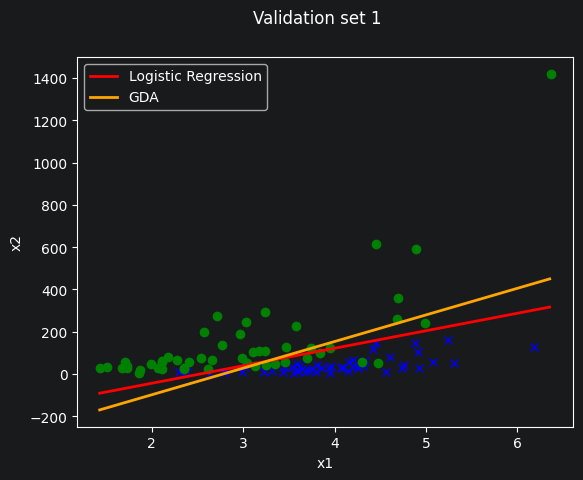

In [154]:
plot(x_valid, y_valid, theta_1=log_reg.theta, legend_1= "Logistic Regression", theta_2= gda.theta , legend_2= "GDA", title= "Validation set 1")

#### (g)

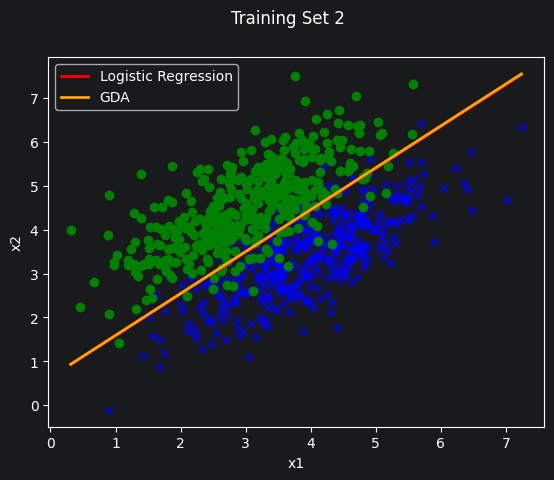

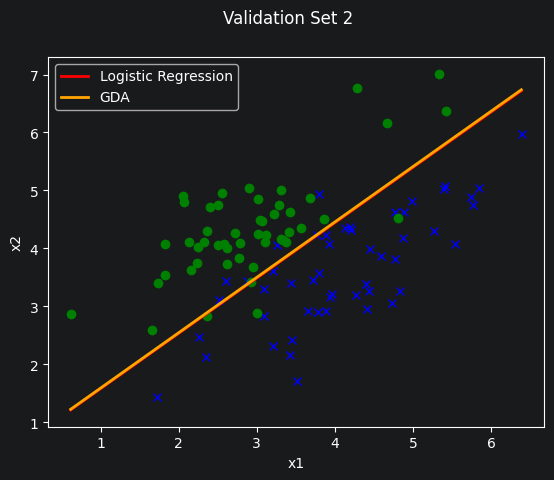

In [155]:
# Dataset 2 paths
datapath2_train = "Data/ds2_train.csv"
datapath2_valid = "Data/ds2_valid.csv"

# Logistic Regression
x_train_lr, y_train = util.load_dataset(datapath2_train, prepend_intercept=True)
log_reg2 = LogisticRegression()
log_reg2.fit(x_train_lr, y_train)

# GDA
x_train_gda, y_train = util.load_dataset(datapath2_train)
gda2 = GDA()
gda2.fit(x_train_gda, y_train)

# Training plot
plot(x_train_gda, y_train, theta_1=log_reg2.theta, legend_1='Logistic Regression',
     theta_2=gda2.theta, legend_2='GDA', title='Training Set 2')

# Validation plot
x_valid_gda, y_valid = util.load_dataset(datapath2_valid)
plot(x_valid_gda, y_valid, theta_1=log_reg2.theta, legend_1='Logistic Regression',
     theta_2=gda2.theta, legend_2='GDA', title='Validation Set 2')

For dataset 2, logistic regression and GDA have same performance.

#### (h)

GDA performs poorly on dataset 1 but OK on dataset 2. The reason is that GDA assumes $p(x \ \vert \ y)$ is Gaussian, whereas dataset 1 is non-Gaussian.

Take a look at dataset 1, we find that all the $x_2$'s are non-negative. Take the logarithm of $x_2$ and train the classifiers:

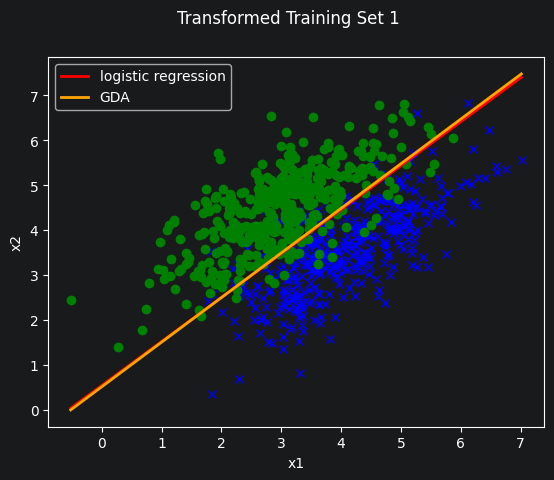

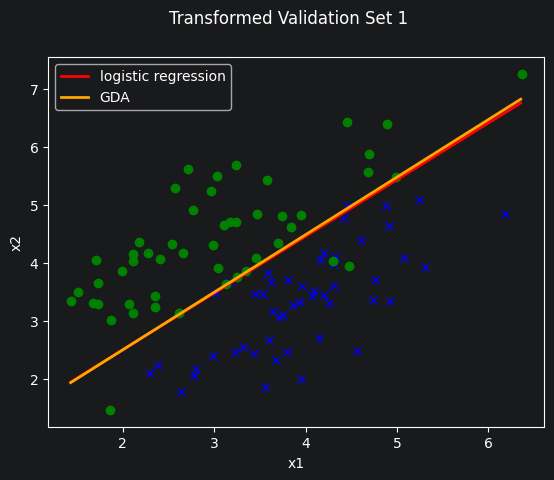

In [156]:
x_train, y_train = util.load_dataset(datapath1_train)
x_valid, y_valid = util.load_dataset(datapath1_valid)
transformed_x_train = np.stack((x_train[:,0], np.log(x_train[:,1])), axis=1)
transformed_x_valid = np.stack((x_valid[:,0], np.log(x_valid[:,1])), axis=1)

# Train logistic regression
transformed_x_train_with_intercept = util.add_intercept(transformed_x_train)
log_reg_h = LogisticRegression()
log_reg_h.fit(transformed_x_train_with_intercept, y_train)

# Train GDA
gda_h = GDA()
gda_h.fit(transformed_x_train, y_train)

# Plot decision boundaries on training set 1
plot(transformed_x_train, y_train, theta_1=log_reg_h.theta, legend_1='logistic regression', theta_2=gda_h.theta, legend_2='GDA', title='Transformed Training Set 1')

# Plot decision boundaries on validation set 1
plot(transformed_x_valid, y_valid, theta_1=log_reg_h.theta, legend_1='logistic regression', theta_2=gda_h.theta, legend_2='GDA', title='Transformed Validation Set 1')

## Part (h) — Log-Transformation to Fix GDA's Gaussian Assumption

### Why GDA Struggled on Dataset 1

GDA assumes that the class-conditional distributions $p(x \mid y)$ are **Gaussian**.
Dataset 1 violates this: all $x_2$ values are **non-negative**, which is impossible
for a true Gaussian (which has support over all of $\mathbb{R}$).

This mismatch between the model's assumption and the data's true distribution causes
GDA to draw a poor decision boundary on dataset 1.

---

### The Fix: Log-Transform $x_2$

If the raw feature $x_2 > 0$ looks log-normal (i.e., $\log x_2$ looks Gaussian),
we can satisfy GDA's assumption by training on the transformed feature.

Define the transformed inputs:

$$\tilde{x}^{(i)} = \begin{bmatrix} x_1^{(i)} \\ \log x_2^{(i)} \end{bmatrix}$$

Since $\log x_2 \in (-\infty, +\infty)$, the transformed feature can plausibly follow
a Gaussian distribution — GDA's core assumption is now much better satisfied.

---

### What the Code Does

`transformed_x_train = np.stack((x_train[:, 0], np.log(x_train[:, 1])), axis=1)`

- `x_train[:, 0]` — keep $x_1$ unchanged
- `np.log(x_train[:, 1])` — replace $x_2$ with $\log x_2$

Both GDA and Logistic Regression are retrained on these transformed features and their decision boundaries plotted.

---

### Key Insight

| Model | Raw Dataset 1 | Log-Transformed Dataset 1 |
|-------|:---:|:---:|
| Logistic Regression | Good (makes no Gaussian assumption) | Good |
| GDA | Poor (Gaussian assumption violated) | **Much Better** |

Logistic Regression is **more robust**: it only models $p(y \mid x)$ directly and never assumes anything about the marginal distribution of $x$.

GDA is a **generative model** that models $p(x \mid y)$ — it's more efficient when the Gaussian assumption holds, but breaks down when the feature distribution is skewed or bounded.

---

### Takeaway

> When features are strictly positive and skewed, a **log-transform** can make them approximately Gaussian, enabling GDA to perform comparably to logistic regression. This illustrates the bias-variance tradeoff between discriminative and generative classifiers: GDA uses stronger assumptions (higher bias), but gains when those assumptions match reality.